# Cobertura del corpus por mes y fuente

Apoyo a «Datos y preparación» del reporte. Leemos la copia histórica de 80.079 registros y contamos los registros por fecha del comentario (`record_date`), no por fecha de descarga. No ejecutamos modelos ni recolectamos datos nuevos.

La figura describe el corpus disponible, no la muestra experimental de 1.000 reseñas ni el número de personas. Los textos repetidos permanecen como registros distintos. Septiembre de 2026 tiene cortes parciales y diferentes por fuente.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/storage-difusion.toml').exists())
source = repo / 'data/inputs/corpus/dataset.parquet'
manifest_path = source.with_name('manifest.json')
manifest = json.loads(manifest_path.read_text())
sha256 = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
assert sha256(source) == manifest['workable']['sha256']
frame = pd.read_parquet(source)
assert len(frame) == manifest['workable']['row_count'] == 80079
assert frame.record_id.is_unique
# La fuente mezcla fechas con precisión de día y de segundo.
# format='mixed' evita convertir silenciosamente una de ellas en valores ausentes.
dates = pd.to_datetime(frame.record_date, format='mixed', utc=True, errors='raise')
assert dates.notna().all()
platforms = ['google_play', 'app_store', 'x', 'youtube']
labels = ['Google Play', 'App Store', 'X', 'YouTube']
assert set(frame.platform.unique()) == set(platforms)
monthly = pd.crosstab(dates.dt.strftime('%Y-%m'), frame.platform).reindex(columns=platforms)
assert int(monthly.to_numpy().sum()) == len(frame)
assert monthly.sum().to_dict() == frame.platform.value_counts().to_dict()
assert int(monthly.loc[['2026-07','2026-08']].to_numpy().sum()) == 15626
coverage = frame[['platform']].assign(date=dates).groupby('platform').date.agg(['min','max','count'])
display(monthly.rename(columns=dict(zip(platforms,labels))))
display(coverage)


platform,Google Play,App Store,X,YouTube
record_date,,,,
2025-09,2896,319,503,153
2025-10,5710,390,501,101
2025-11,5240,389,500,98
2025-12,5537,453,508,101
2026-01,5503,448,502,110
2026-02,4661,345,507,58
2026-03,5117,329,501,55
2026-04,4787,666,506,60
2026-05,4954,418,505,75


,min,max,count
platform,,,
app_store,2025-09-01 00:00:00+00:00,2026-09-18 01:29:51+00:00,5201
google_play,2025-09-13 01:53:42+00:00,2026-09-26 21:45:54+00:00,66997
x,2025-09-01 13:34:27+00:00,2026-09-14 23:54:01+00:00,6553
youtube,2025-09-01 04:33:28+00:00,2026-09-16 20:18:39+00:00,1328


## Lectura de la cobertura

Google Play aporta la mayoría de los registros. Los cambios de altura reflejan comentarios disponibles para cada mes y pueden depender de la captura; no prueban cambios en la frecuencia real de problemas. La fecha final del corpus es el 26 de septiembre de 2026, pero las demás fuentes terminan antes. Julio y agosto son la ventana fijada para la comparación integrada; esta libreta no modifica esa selección.

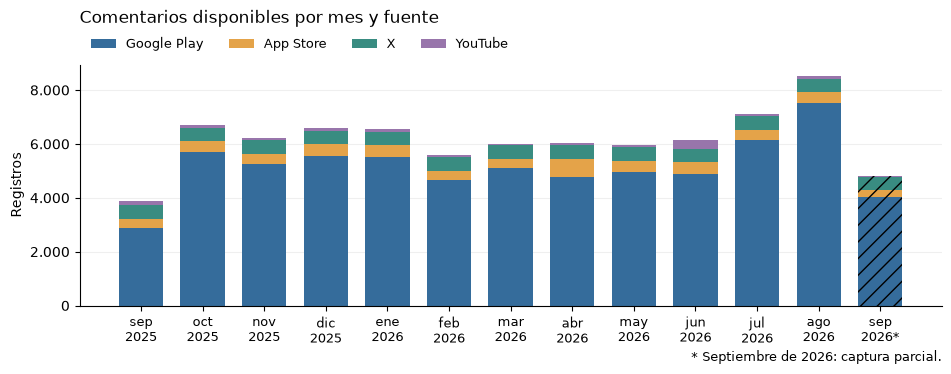

In [2]:
fig, ax = plt.subplots(figsize=(9.4, 3.6), layout='constrained')
colors = ['#356C9B', '#E4A349', '#398C81', '#9875AB']
bottom = pd.Series(0, index=monthly.index)
for platform, label, color in zip(platforms, labels, colors):
    bars = ax.bar(range(len(monthly)), monthly[platform], bottom=bottom, label=label,
                  color=color, width=.72)
    bars[-1].set_hatch('//')
    bottom += monthly[platform]
month_names = ['ene','feb','mar','abr','may','jun','jul','ago','sep','oct','nov','dic']
ticks = [f'{month_names[int(m[5:])-1]}\n{m[:4]}' for m in monthly.index]
ticks[-1] += '*'
ax.set_xticks(range(len(monthly)), ticks, fontsize=9)
ax.set_ylabel('Registros')
ax.set_title('Comentarios disponibles por mes y fuente', loc='left', fontsize=12, pad=30)
ax.yaxis.set_major_formatter(FuncFormatter(lambda n, _: f'{n:,.0f}'.replace(',', '.')))
ax.legend(ncol=4, loc='lower left', bbox_to_anchor=(0, 1.01), frameon=False, fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=.2)
ax.text(1, -.23, '* Septiembre de 2026: captura parcial.', transform=ax.transAxes,
        ha='right', fontsize=9)
display(fig)
plt.close(fig)


## Exportación para el reporte

Cada ejecución crea una carpeta fechada con CSV agregado, figura PNG/PDF y procedencia. Los hashes verifican identidad de archivos; no certifican representatividad. No se exportan textos ni identificadores individuales.

In [3]:
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
export_root = repo / 'reports/drafts/difusion/exports/cobertura-del-corpus'
output = export_root / stamp
output.mkdir(parents=True, exist_ok=False)
monthly.rename_axis('month').to_csv(output / 'registros-por-mes-y-fuente.csv')
coverage.to_csv(output / 'cobertura-por-fuente.csv')
fig.savefig(output / 'corpus-mensual.png', dpi=200, bbox_inches='tight')
fig.savefig(output / 'corpus-mensual.pdf', bbox_inches='tight')
provenance = {
    'source': str(source.relative_to(repo)), 'source_sha256': sha256(source),
    'manifest_sha256': sha256(manifest_path), 'rows': len(frame),
    'distinct_texts': int(frame.text_hash.nunique()),
    'date_min': dates.min().isoformat(), 'date_max': dates.max().isoformat(),
    'date_column': 'record_date', 'missing_dates': int(dates.isna().sum()),
    'partial_month': '2026-09', 'selected_window_rows': 15626,
    'snapshot_created_at': manifest['created_at'],
    'source_date_precision': frame.date_precision.value_counts().to_dict(),
    'models_executed': 0,
    'limitations': ['Counts are records, not people; duplicate texts retained.',
                    'Per-source coverage ends on different dates.',
                    'Capture volume is not prevalence of app problems.']}
(output / 'procedencia.json').write_text(json.dumps(provenance, ensure_ascii=False, indent=2)+'\n')
files = {p.name: sha256(p) for p in sorted(output.iterdir())}
(output / 'manifest.json').write_text(json.dumps({'files':files}, indent=2)+'\n')
(export_root / 'latest.json').write_text(json.dumps({'directory':stamp, 'manifest_sha256':sha256(output/'manifest.json')}, indent=2)+'\n')
print(f'Exportación: reports/drafts/difusion/exports/cobertura-del-corpus/{stamp}')


Exportación: reports/difusion/exports/cobertura-del-corpus/20261105T211948445522Z
